# Lab 6.2: A Global Explanation Report for a Claims Frequency Model

Run the cells from top to bottom. You do not need to change any code until the optional last section. Each checkpoint tells you what to look for.

Data: freMTPL2freq, 678,013 French motor third-party liability policies (OpenML data_id 41214, listed there as CC0; original source the CASdatasets R package, GPL >= 2). The model predicts claims per policy-year. This notebook reproduces the data case study of Chapter 6 and the numbers in its figures.

## 1. Load the data and fit the model

In [1]:
import tempfile, itertools, time
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance, r2_score
from sklearn.tree import DecisionTreeRegressor, export_text

T0 = time.time()
TMP = Path(tempfile.gettempdir()) / "xai-ch06"
df = fetch_openml(data_id=41214, as_frame=True, data_home=str(TMP)).frame
df["ClaimNb"] = df["ClaimNb"].clip(upper=4)          # a few policies report up to 16 claims
df["Exposure"] = df["Exposure"].clip(upper=1)        # exposure is in years
df["VehGas"] = df["VehGas"].astype(str).str.strip("'")
df["LogDensity"] = np.log(df["Density"])
for c in ["Area", "VehBrand", "VehGas", "Region"]:
    df[c] = df[c].astype("category")
F = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand", "VehGas", "Area", "LogDensity", "Region"]
y, w = df.ClaimNb / df.Exposure, df.Exposure
Xtr, Xte, ytr, yte, wtr, wte = train_test_split(df[F], y, w, test_size=0.33, random_state=0)

def fit(cols):
    m = HistGradientBoostingRegressor(loss="poisson", max_leaf_nodes=31, learning_rate=0.1, max_iter=300,
                                      categorical_features="from_dtype", early_stopping=True,
                                      validation_fraction=0.1, random_state=0)
    return m.fit(Xtr[cols], ytr, sample_weight=wtr)

def dev(model, X, cols):
    return mean_poisson_deviance(yte, np.clip(model.predict(X[cols]), 1e-6, None), sample_weight=wte)

m = fit(F)
base = dev(m, Xte, F)
const = mean_poisson_deviance(yte, np.full(len(yte), np.average(ytr, weights=wtr)), sample_weight=wte)
print("policies:", len(df))
print("claims per policy-year: %.3f" % (df.ClaimNb.sum() / df.Exposure.sum()))
print("share of policies with no claim: %.3f" % (df.ClaimNb == 0).mean())
print("test Poisson deviance: model %.4f, constant rate %.4f" % (base, const))

policies: 678013
claims per policy-year: 0.101
share of policies with no claim: 0.950
test Poisson deviance: model 0.5710, constant rate 0.6220


**Checkpoint 1.** 678,013 policies, about 0.101 claims per policy-year, about 95 percent of policies with no claim, and a test deviance near 0.571 for the model against 0.622 for a constant rate. A global explanation is only worth computing for a model that beats the baseline.

## 2. Which inputs does the model lean on? Permutation importance and LOFO

In [2]:
rng = np.random.default_rng(0)

def permute(X, cols):
    Xp, idx = X.copy(), rng.permutation(len(X))
    for c in cols:
        Xp[c] = X[c].values[idx]
        if str(X[c].dtype) == "category":
            Xp[c] = pd.Categorical(Xp[c], categories=X[c].cat.categories)
    return Xp

perm = {f: [dev(m, permute(Xte, [f]), F) - base for _ in range(5)] for f in F}
lofo = {}
for f in F:
    cols = [c for c in F if c != f]
    lofo[f] = dev(fit(cols), Xte, cols) - base
tab = pd.DataFrame({"permutation": {f: np.mean(v) for f, v in perm.items()},
                    "perm_sd": {f: np.std(v) for f, v in perm.items()},
                    "LOFO": lofo}).sort_values("permutation", ascending=False)
tab.round(4)

,permutation,perm_sd,LOFO
BonusMalus,0.0409,0.0009,0.0189
VehAge,0.0400,0.0005,0.0214
VehBrand,0.0190,0.0003,0.0044
DrivAge,0.0119,0.0005,0.0026
VehPower,0.0091,0.0002,0.0042
VehGas,0.0064,0.0002,0.0021
Region,0.0061,0.0005,0.0003
LogDensity,0.0057,0.0005,-0.0000
Area,0.0007,0.0001,0.0003


**Checkpoint 2.** Bonus-malus and vehicle age lead the permutation ranking (about 0.04 each), and both stay on top in LOFO, but at about half the size. Population density shows a permutation importance of about 0.006 and a LOFO of almost exactly zero. The area code is near zero on both.

In [3]:
cols = [c for c in F if c not in ("Area", "LogDensity")]
print("permute Area and LogDensity together: %.4f" % np.mean([dev(m, permute(Xte, ["Area", "LogDensity"]), F) - base for _ in range(5)]))
print("drop both and retrain (group LOFO):   %.4f" % (dev(fit(cols), Xte, cols) - base))
print(pd.crosstab(df.Area, pd.cut(df.LogDensity, [-1, 3, 4, 5, 6, 7, 8, 11])))

permute Area and LogDensity together: 0.0054


drop both and retrain (group LOFO):   0.0011


LogDensity  (-1, 3]  (3, 4]  (4, 5]  (5, 6]  (6, 7]  (7, 8]  (8, 11]
Area                                                                
A             35201   68756       0       0       0       0        0
B                 0    9435   66024       0       0       0        0
C                 0       0   45915  118847   27118       0        0
D                 0       0       0       0   82124   69472        0
E                 0       0       0       0       0   28753   108414
F                 0       0       0       0       0       0    17954


**Checkpoint 3.** The crosstab shows that the area code is a banding of population density: each area covers a narrow band of log density. Dropping either one costs almost nothing because the other carries the same information; dropping both costs about 0.001. Write down which of the two numbers (permutation or LOFO) answers the question *does the model use density?* and which answers *does the data need density?*

## 3. What shape is the effect? Partial dependence and ICE

In [4]:
P = Xte.sample(2000, random_state=1)

def pdp_matrix(P, f, grid):
    rows = []
    for g in grid:
        X = P.copy(); X[f] = g
        rows.append(m.predict(X[F]))
    return np.array(rows)

ga = np.arange(18, 91, 1)
A = pdp_matrix(P, "DrivAge", ga)
pa = A.mean(1)
print("PDP driver age 18, 30, 50, 80:", np.round(pa[[0, 12, 32, 62]], 3))
gb = np.arange(50, 151, 5)
pb = pdp_matrix(P, "BonusMalus", gb).mean(1)
print("PDP bonus-malus 50, 100, 150:", np.round(pb[[0, 10, 20]], 3))
C = A - A[12]                      # centered ICE: each policy relative to itself at age 30
print("centered ICE at age 18, deciles 10/50/90:", np.round(np.quantile(C[0], [0.1, 0.5, 0.9]), 3))
print("centered ICE at age 90, deciles 10/50/90:", np.round(np.quantile(C[-1], [0.1, 0.5, 0.9]), 3))

PDP driver age 18, 30, 50, 80: [0.231 0.108 0.131 0.128]


PDP bonus-malus 50, 100, 150: [0.091 0.251 0.452]
centered ICE at age 18, deciles 10/50/90: [0.011 0.081 0.247]
centered ICE at age 90, deciles 10/50/90: [-0.008  0.048  0.126]


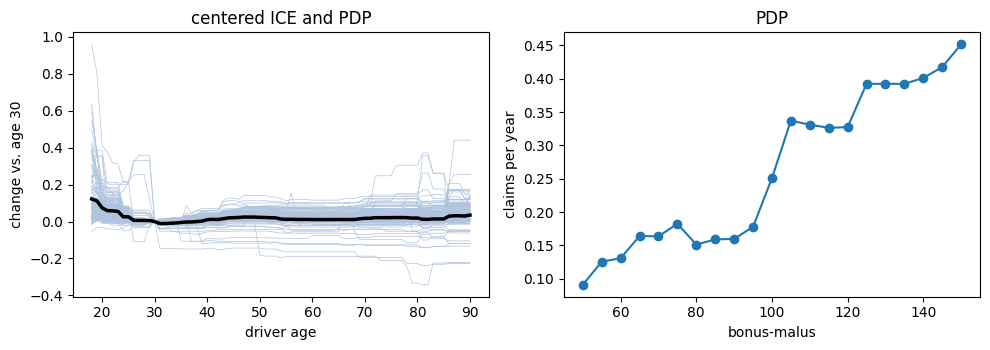

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for j in np.random.default_rng(4).choice(A.shape[1], 150, replace=False):
    ax[0].plot(ga, C[:, j], color="lightsteelblue", lw=0.5)
ax[0].plot(ga, pa - pa[12], color="black", lw=2.5)
ax[0].set(xlabel="driver age", ylabel="change vs. age 30", title="centered ICE and PDP")
ax[1].plot(gb, pb, marker="o"); ax[1].set(xlabel="bonus-malus", ylabel="claims per year", title="PDP")
plt.tight_layout(); plt.show()

**Checkpoint 4.** The average curve for driver age falls steeply from 18 to the early thirties and then stays fairly flat. The ICE curves fan out: at age 18 the change relative to age 30 ranges from small to large across policies, which is a sign of interaction. The bonus-malus curve rises from about 0.09 at level 50 to well above 0.3 at the top of the scale.

## 4. When features move together: accumulated local effects

drivers aged 18-21: 11253, with bonus-malus <= 60: 4.7%
correlation driver age vs bonus-malus: -0.48


young-driver effect at 18: ALE +0.059, PDP +0.116


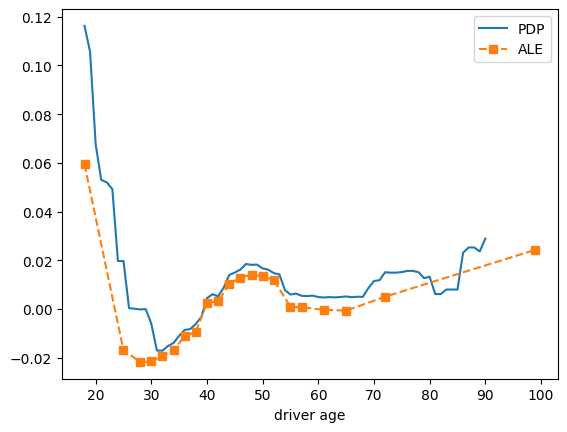

In [6]:
young = df[df.DrivAge <= 21]
print("drivers aged 18-21: %d, with bonus-malus <= 60: %.1f%%" % (len(young), 100 * (young.BonusMalus <= 60).mean()))
print("correlation driver age vs bonus-malus: %.2f" % df[["DrivAge", "BonusMalus"]].corr().iloc[0, 1])

def ale_curve(X, f, K=20):
    q = np.unique(np.quantile(X[f], np.linspace(0, 1, K + 1)))
    z = np.clip(np.digitize(X[f], q[1:-1], right=True), 0, len(q) - 2)
    eff, cnt = [], []
    for k in range(len(q) - 1):
        Xk = X[z == k]
        lo, hi = Xk.copy(), Xk.copy()
        lo[f], hi[f] = q[k], q[k + 1]
        eff.append(np.mean(m.predict(hi[F]) - m.predict(lo[F])) if len(Xk) else 0.0)
        cnt.append(len(Xk))
    acc = np.concatenate([[0.0], np.cumsum(eff)])
    mid = (acc[:-1] + acc[1:]) / 2
    return q, acc - np.average(mid, weights=cnt)

SA = Xte.sample(20000, random_state=2)
q, a = ale_curve(SA, "DrivAge")
pdc = pa - m.predict(SA[F]).mean()
print("young-driver effect at 18: ALE %+.3f, PDP %+.3f" % (a[0], pdc[0]))
plt.plot(ga, pdc, label="PDP"); plt.plot(q, a, "--s", label="ALE"); plt.legend(); plt.xlabel("driver age"); plt.show()

**Checkpoint 5.** Driver age and bonus-malus are negatively correlated (about -0.48): new drivers start at 100 and move down with claim-free years. The PDP's young-driver effect is roughly twice the ALE's. The PDP evaluates the model on combinations such as an 18-year-old at the best bonus-malus level, which are rare in the data; ALE only uses changes within each age band.

## 5. Do features work alone? Friedman's H-statistic

In [7]:
S = Xte.sample(300, random_state=3)[F].reset_index(drop=True)
n = len(S)
big = S.loc[np.tile(np.arange(n), n)].reset_index(drop=True)

def pd_at(cols):
    X = big.copy()
    own = S.loc[np.repeat(np.arange(n), n), cols].reset_index(drop=True)
    for c in cols:
        X[c] = own[c].values
        if str(S[c].dtype) == "category":
            X[c] = pd.Categorical(X[c], categories=S[c].cat.categories)
    v = np.log(m.predict(X[F])).reshape(n, n).mean(1)
    return v - v.mean()

cand = ["DrivAge", "BonusMalus", "VehAge", "VehPower", "VehBrand", "VehGas", "LogDensity"]
single = {c: pd_at([c]) for c in cand}
res = []
for a_, b_ in itertools.combinations(cand, 2):
    j = pd_at([a_, b_])
    res.append((np.sqrt(((j - single[a_] - single[b_]) ** 2).sum() / (j ** 2).sum()), a_, b_))
for h, a_, b_ in sorted(res, reverse=True)[:6]:
    print("H %.3f  %s x %s" % (h, a_, b_))

H 0.768  VehBrand x VehGas
H 0.586  VehPower x VehBrand
H 0.529  VehAge x VehBrand
H 0.339  DrivAge x VehBrand
H 0.263  DrivAge x BonusMalus
H 0.257  VehBrand x LogDensity


**Checkpoint 6.** Driver age and bonus-malus form the strongest interaction in this model. Rerun the cell with `random_state=4` in the sample: the order of the weaker pairs changes, the top pair should not. H is noisy at small samples; report it with the sample size.

## 6. A model of the model: a global surrogate tree

In [8]:
lp_tr, lp_te = np.log(m.predict(Xtr[F])), np.log(m.predict(Xte[F]))
cats = ["VehBrand", "VehGas", "Area", "Region"]
Ztr = pd.get_dummies(Xtr[F], columns=cats)
Zte = pd.get_dummies(Xte[F], columns=cats).reindex(columns=Ztr.columns, fill_value=0)
for d in range(1, 9):
    t = DecisionTreeRegressor(max_depth=d, min_samples_leaf=500, random_state=0).fit(Ztr, lp_tr, sample_weight=wtr)
    print(d, "fidelity R2 %.3f" % r2_score(lp_te, t.predict(Zte), sample_weight=wte))
t3 = DecisionTreeRegressor(max_depth=3, min_samples_leaf=500, random_state=0).fit(Ztr, lp_tr, sample_weight=wtr)
print(export_text(t3, feature_names=list(Ztr.columns), decimals=1))

1 fidelity R2 0.262


2 fidelity R2 0.467


3 fidelity R2 0.588


4 fidelity R2 0.678


5 fidelity R2 0.737


6 fidelity R2 0.781


7 fidelity R2 0.811


8 fidelity R2 0.831


|--- BonusMalus <= 57.5
|   |--- VehAge <= 0.5
|   |   |--- VehBrand_B12 <= 0.5
|   |   |   |--- value: [-2.2]
|   |   |--- VehBrand_B12 >  0.5
|   |   |   |--- value: [-1.2]
|   |--- VehAge >  0.5
|   |   |--- VehAge <= 12.5
|   |   |   |--- value: [-2.6]
|   |   |--- VehAge >  12.5
|   |   |   |--- value: [-3.0]
|--- BonusMalus >  57.5
|   |--- BonusMalus <= 95.5
|   |   |--- DrivAge <= 38.5
|   |   |   |--- value: [-2.3]
|   |   |--- DrivAge >  38.5
|   |   |   |--- value: [-1.9]
|   |--- BonusMalus >  95.5
|   |   |--- BonusMalus <= 109.5
|   |   |   |--- value: [-1.3]
|   |   |--- BonusMalus >  109.5
|   |   |   |--- value: [-1.1]



**Checkpoint 7.** Fidelity rises with depth but slowly: a depth-3 tree reproduces well under half of the variation in the model's log predictions, and even depth 8 leaves a large part unexplained. The depth-3 tree splits on bonus-malus, vehicle age and driver age, which matches the importance ranking. Note the fidelity next to every rule you quote.

In [9]:
leaf = t3.apply(Zte)
for l in np.unique(leaf):
    s = leaf == l
    r2 = 1 - np.mean((lp_te[s] - t3.predict(Zte)[s]) ** 2) / np.var(lp_te[s])
    print("leaf %2d: %6d policies, prediction %.3f, within-leaf variance left %.3f" % (l, s.sum(), np.exp(t3.predict(Zte)[s][0]), np.var(lp_te[s])))
print("minutes:", round((time.time() - T0) / 60, 1))

leaf  3:   5116 policies, prediction 0.116, within-leaf variance left 0.055
leaf  4:   8332 policies, prediction 0.313, within-leaf variance left 0.559
leaf  6: 109649 policies, prediction 0.074, within-leaf variance left 0.068
leaf  7:  26372 policies, prediction 0.052, within-leaf variance left 0.106


leaf 10:  43434 policies, prediction 0.103, within-leaf variance left 0.204


leaf 11:  21718 policies, prediction 0.154, within-leaf variance left 0.190
leaf 13:   7162 policies, prediction 0.261, within-leaf variance left 0.154
leaf 14:   1962 policies, prediction 0.340, within-leaf variance left 0.133
minutes: 2.3


**Checkpoint 8.** Some leaves are tight (little variance left) and some are wide. A surrogate can be faithful in one region and loose in another; report fidelity where you use the rule, not only overall.

## 7. Optional: your own check

Pick one claim from your report (for example, "bonus-malus is the most important feature") and test whether it survives a different random split (`random_state=1` in `train_test_split`) and a model with `max_leaf_nodes=15`. Record which claims are stable and which are not.